# CHUV signal baselines

Loads each XDF file with `bmiemg.prune` and summarizes the eight columns before the final trigger column.

In [1]:
%pip install --upgrade pip
%pip install -q numpy scipy matplotlib polars pyxdf mne pyyaml tqdm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [14]:
from __future__ import annotations

import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from scipy import signal

from bmiemg.prune.adapters.file_loaders.xdf_loader import XdfLoader

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").exists())
DATA_DIR = ROOT / "data" / "bids" / "2026-10-14"
INCLUDE_OLD_FILES = False
CHANNEL_INDICES: list[int] | None = None
TRACE_START_S = 30.0
TRACE_DURATION_S = 10.0
PSD_DURATION_S = 60.0

xdf_files = sorted(DATA_DIR.rglob("*.xdf"))
if not INCLUDE_OLD_FILES:
    xdf_files = [path for path in xdf_files if "_old" not in path.stem]
if not xdf_files:
    raise FileNotFoundError(f"No XDF files found below {DATA_DIR}")


In [15]:
def scalar(value, default=None):
    return value[0] if isinstance(value, list) and value else value if value is not None else default


def load_channels(path: Path) -> tuple[np.ndarray, np.ndarray, dict]:
    actor = XdfLoader().load_file(path)
    streams = [stream for stream in actor.streams if np.asarray(stream.get("time_series", [])).ndim == 2]
    stream = max(streams, key=lambda item: np.asarray(item["time_series"]).size)
    raw = np.asarray(stream["time_series"], dtype=float)
    columns = np.asarray(CHANNEL_INDICES if CHANNEL_INDICES is not None else range(raw.shape[1] - 9, raw.shape[1] - 1))
    columns = np.where(columns < 0, raw.shape[1] + columns, columns)
    if len(columns) != 8 or np.any(columns < 0) or np.any(columns >= raw.shape[1]):
        raise ValueError(f"Expected eight valid channel indices, got {columns.tolist()}")
    metadata = {
        "recording": path.stem,
        "session": next(part for part in path.parts if part.startswith("ses-")),
        "sfreq": float(scalar(stream["info"].get("nominal_srate"))),
        "columns": (columns + 1).tolist(),
    }
    data = raw[:, columns].copy()
    timestamps = np.asarray(stream["time_stamps"], dtype=float).copy()
    del raw, stream, streams, actor
    gc.collect()
    return data, timestamps, metadata


def band_power(frequencies: np.ndarray, spectrum: np.ndarray, low: float, high: float) -> float:
    keep = (frequencies >= low) & (frequencies <= high)
    return float(np.trapezoid(spectrum[keep], frequencies[keep])) if keep.sum() > 1 else np.nan


def flat_percentage(values: np.ndarray, sfreq: float, duration_s: float = 0.1) -> float:
    unchanged = np.diff(values) == 0
    edges = np.diff(np.r_[False, unchanged, False].astype(int))
    lengths = np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1) + 1
    return 100 * lengths[lengths >= duration_s * sfreq].sum() / len(values)


def channel_metrics(values: np.ndarray, sfreq: float) -> dict:
    finite = np.isfinite(values)
    clean = values[finite]
    median = float(np.median(clean))
    centered = clean - median
    differences = np.abs(np.diff(clean))
    frequencies, spectrum = signal.welch(centered, fs=sfreq, nperseg=min(len(clean), int(4 * sfreq)))
    emg_power = band_power(frequencies, spectrum, 20.0, min(450.0, 0.45 * sfreq))
    p005, p995 = np.percentile(clean, [0.5, 99.5])
    minimum, maximum = float(clean.min()), float(clean.max())
    return {
        "finite_pct": 100 * finite.mean(),
        "median_uv": median,
        "min_uv": minimum,
        "max_uv": maximum,
        "full_p2p_uv": maximum - minimum,
        "p0.5_uv": float(p005),
        "p99.5_uv": float(p995),
        "robust_p2p_uv": float(p995 - p005),
        "centered_rms_uv": float(np.sqrt(np.mean(centered**2))),
        "flat_100ms_pct": flat_percentage(clean, sfreq),
        "min_or_max_pct": 100 * np.mean((clean == minimum) | (clean == maximum)),
        "p99_abs_step_uv": float(np.percentile(differences, 99)),
        "max_abs_step_uv": float(differences.max()),
        "power_50hz_to_emg": band_power(frequencies, spectrum, 48.0, 52.0) / emg_power,
        "power_0.5_10hz_to_emg": band_power(frequencies, spectrum, 0.5, 10.0) / emg_power,
    }


In [16]:
timing_rows, channel_rows = [], []
preview = None

for path in xdf_files:
    data, timestamps, metadata = load_channels(path)
    dt = np.diff(timestamps)
    median_dt = float(np.median(dt))
    timing_rows.append({
        "session": metadata["session"],
        "recording": metadata["recording"],
        "samples": len(timestamps),
        "duration_s": float(timestamps[-1] - timestamps[0]),
        "nominal_hz": metadata["sfreq"],
        "measured_hz": 1 / median_dt,
        "p99_timestamp_jitter_us": 1e6 * float(np.percentile(np.abs(dt - median_dt), 99)),
        "max_gap_ms": 1e3 * float(dt.max()),
    })
    for index, column in enumerate(metadata["columns"]):
        row = channel_metrics(data[:, index], metadata["sfreq"])
        row.update(session=metadata["session"], channel=f"EMG {index + 1}", xdf_column=column)
        channel_rows.append(row)
    if preview is None:
        start = min(int(TRACE_START_S * metadata["sfreq"]), len(data) - 1)
        stop = min(len(data), start + int(max(TRACE_DURATION_S, PSD_DURATION_S) * metadata["sfreq"]))
        preview = {"data": data[start:stop].copy(), "metadata": metadata, "start_s": start / metadata["sfreq"]}
    del data, timestamps
    gc.collect()

timing = pl.DataFrame(timing_rows)
channels = pl.DataFrame(channel_rows)


## Numeric summaries

In [17]:
display(timing.with_columns(pl.selectors.numeric().round(3)))
display(channels.with_columns(pl.selectors.numeric().round(4)).sort(["session", "channel"]))

session,recording,samples,duration_s,nominal_hz,measured_hz,p99_timestamp_jitter_us,max_gap_ms
str,str,i64,f64,f64,f64,f64,f64
"""ses-S001""","""sub-P015_ses-S001_task-Default…",1748942,1708.006,1024.0,1023.967,0.0,0.977
"""ses-S002""","""sub-P015_ses-S002_task-Default…",368633,360.004,1024.0,1023.966,0.0,0.977
"""ses-S003""","""sub-P015_ses-S003_task-Default…",1478103,1443.506,1024.0,1023.967,0.0,0.977


finite_pct,median_uv,min_uv,max_uv,full_p2p_uv,p0.5_uv,p99.5_uv,robust_p2p_uv,centered_rms_uv,flat_100ms_pct,min_or_max_pct,p99_abs_step_uv,max_abs_step_uv,power_50hz_to_emg,power_0.5_10hz_to_emg,session,channel,xdf_column
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,i64
100.0,-2905.798,-3121.848,-819.5,2302.348,-2972.252,-2835.172,137.08,29.2387,0.0,0.0001,38.144,1291.234,0.1292,0.0833,"""ses-S001""","""EMG 1""",169
100.0,-13103.656,-13382.286,-9879.594,3502.692,-13184.414,-13013.958,170.456,38.7338,0.0,0.0001,36.952,1860.414,0.1751,0.1178,"""ses-S001""","""EMG 2""",170
100.0,-12614.042,-12806.55,-10246.432,2560.118,-12693.012,-12524.642,168.37,38.1629,0.0,0.0001,35.462,1430.698,0.117,0.0928,"""ses-S001""","""EMG 3""",171
100.0,-2561.012,-3713.08,-1009.326,2703.754,-2640.28,-2474.294,165.986,38.6806,0.0,0.0001,36.356,668.712,0.0941,0.1222,"""ses-S001""","""EMG 4""",172
100.0,-4968.852,-7684.526,-2064.842,5619.684,-5110.7,-4804.356,306.344,77.4573,0.0,0.0001,37.846,1804.39,0.2235,0.1951,"""ses-S001""","""EMG 5""",173
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
100.0,-2658.458,-2758.288,-2556.542,201.746,-2717.462,-2597.964,119.498,25.1899,0.0,0.0001,36.356,72.414,0.0882,0.0643,"""ses-S003""","""EMG 4""",172
100.0,-5172.386,-5333.902,-5018.32,315.582,-5274.004,-5072.854,201.15,47.1067,0.0,0.0001,38.144,89.698,0.2209,0.0917,"""ses-S003""","""EMG 5""",173
100.0,-6247.272,-6401.04,-6099.762,301.278,-6346.208,-6149.528,196.68,45.5924,0.0,0.0001,37.25,97.446,0.139,0.0993,"""ses-S003""","""EMG 6""",174


## Visualizations

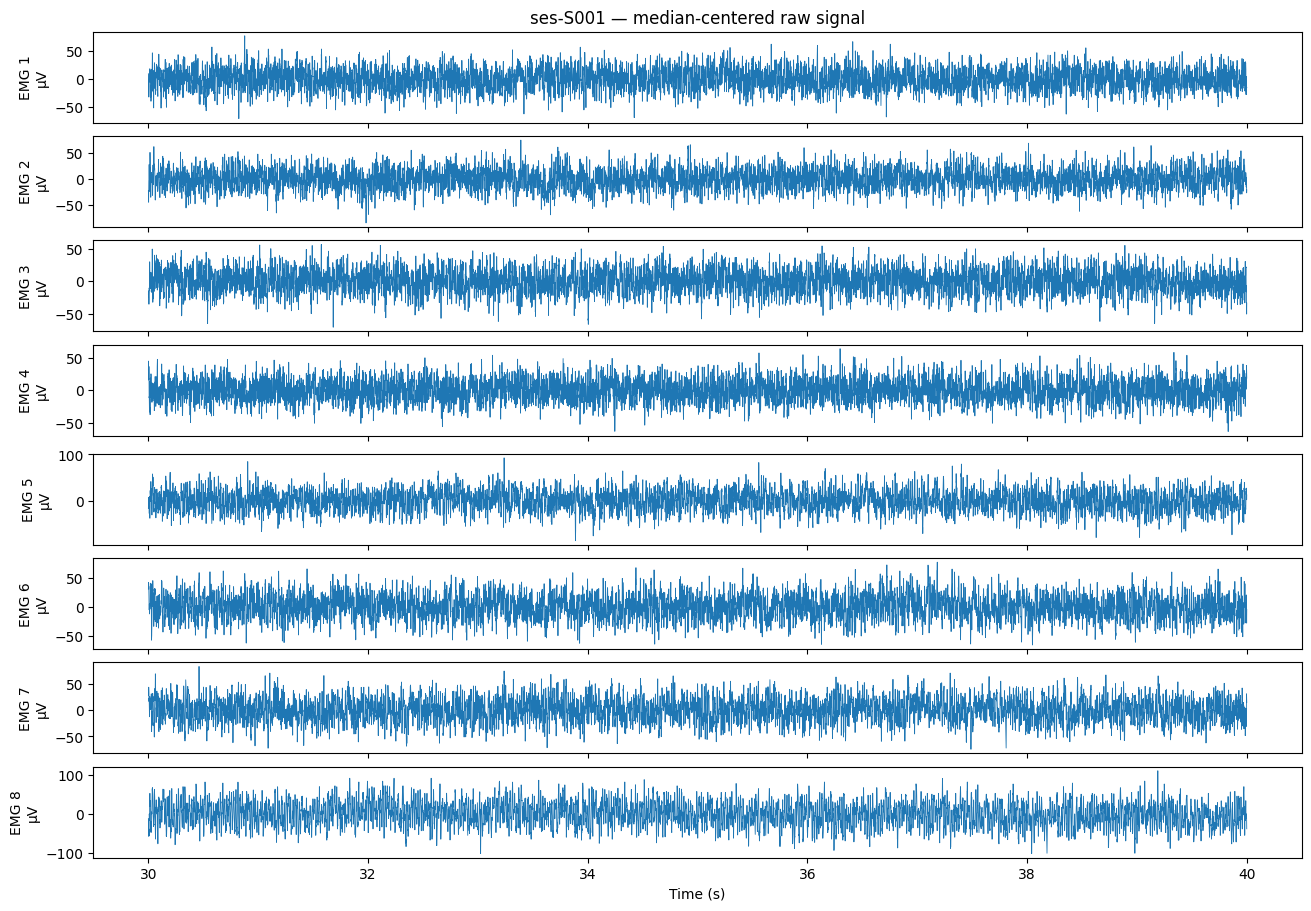

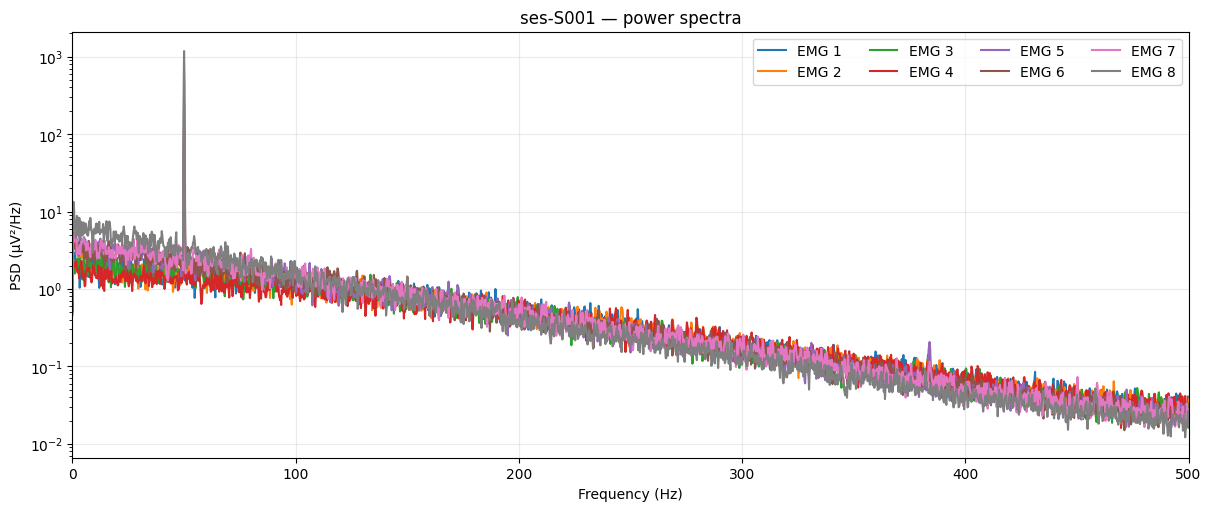

In [18]:
data = preview["data"]
metadata = preview["metadata"]
sfreq = metadata["sfreq"]
trace_n = min(len(data), int(TRACE_DURATION_S * sfreq))
time = preview["start_s"] + np.arange(trace_n) / sfreq

fig, axes = plt.subplots(8, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
for index, axis in enumerate(axes):
    values = data[:trace_n, index]
    axis.plot(time, values - np.median(values), linewidth=0.6)
    axis.set_ylabel(f"EMG {index + 1}\nµV")
axes[0].set_title(f"{metadata['session']} — median-centered raw signal")
axes[-1].set_xlabel("Time (s)")
plt.show()

fig, axis = plt.subplots(figsize=(12, 5), constrained_layout=True)
for index in range(8):
    values = data[:, index] - np.median(data[:, index])
    frequencies, spectrum = signal.welch(values, fs=sfreq, nperseg=min(len(values), int(4 * sfreq)))
    axis.semilogy(frequencies, spectrum, label=f"EMG {index + 1}")
axis.set(xlim=(0, min(500, sfreq / 2)), xlabel="Frequency (Hz)", ylabel="PSD (µV²/Hz)", title=f"{metadata['session']} — power spectra")
axis.legend(ncol=4)
axis.grid(alpha=0.25)
plt.show()

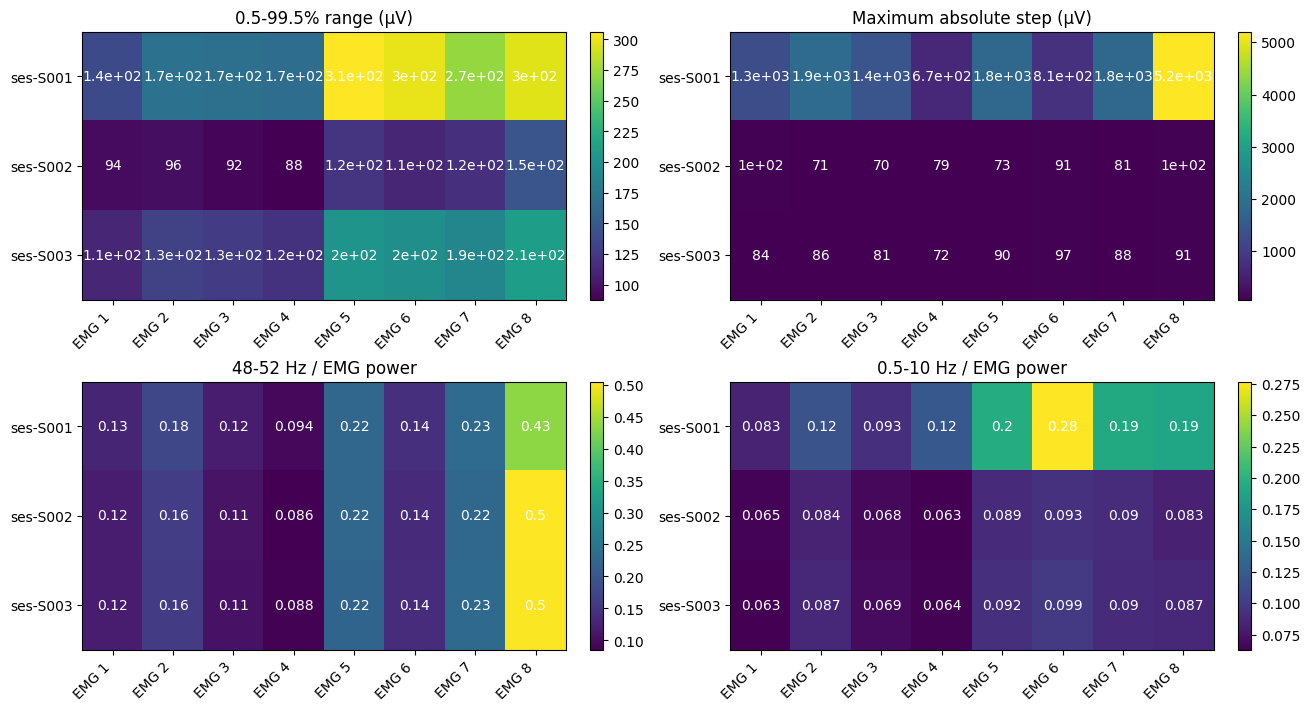

In [19]:
sessions = sorted(channels["session"].unique().to_list())
channel_names = [f"EMG {index}" for index in range(1, 9)]
metrics = [
    ("robust_p2p_uv", "0.5-99.5% range (µV)"),
    ("max_abs_step_uv", "Maximum absolute step (µV)"),
    ("power_50hz_to_emg", "48-52 Hz / EMG power"),
    ("power_0.5_10hz_to_emg", "0.5-10 Hz / EMG power"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
for axis, (metric, title) in zip(axes.flat, metrics):
    lookup = {(row["session"], row["channel"]): row[metric] for row in channels.iter_rows(named=True)}
    matrix = np.array([[lookup[(session_name, channel)] for channel in channel_names] for session_name in sessions])
    image = axis.imshow(matrix, aspect="auto", cmap="viridis")
    axis.set_xticks(range(8), channel_names, rotation=45, ha="right")
    axis.set_yticks(range(len(sessions)), sessions)
    axis.set_title(title)
    for row in range(len(sessions)):
        for column in range(8):
            axis.text(column, row, f"{matrix[row, column]:.2g}", ha="center", va="center", color="white")
    fig.colorbar(image, ax=axis)
plt.show()

## Interpretation

The recordings are temporally continuous. The main observations are persistent 50 Hz contamination, especially on EMG 8, and large synchronized transients in session S001.

| Session | Duration | Median robust range | Median RMS | Largest step | Maximum 50 Hz ratio |
|---|---:|---:|---:|---:|---:|
| S001 | 1708 s | 221 µV | 53.0 µV | 5204 µV | 0.434 |
| S002 | 360 s | 104 µV | 20.1 µV | 103 µV | 0.505 |
| S003 | 1444 s | 159 µV | 34.6 µV | 97 µV | 0.501 |

- Sampling is stable at approximately 1023.97 Hz against the nominal 1024 Hz. The maximum timestamp interval is 0.977 ms, approximately one sample, with no larger gaps.
- All channels contain 100% finite samples. No unchanged runs longer than 100 ms were found.
- S002 is six minutes long, compared with approximately 28 minutes for S001 and 24 minutes for S003. Confirm whether this duration was intentional.
- S001 contains a recording-wide discontinuity at 1284.018 seconds. It affects all eight channels simultaneously, reaching 5.2 mV on EMG 8 and 1.3–1.9 mV on several other channels. Another smaller event occurs near 1112 seconds. This is consistent with a common movement, cable, reference, or acquisition event rather than independent channel noise.
- The displayed 30–40 second trace does not contain these events because they occur later in S001.
- EMG 8 has the strongest narrow 50 Hz component in every session. Its 48–52 Hz power is 43–50% of the complete 20–450 Hz power. EMG 5 and EMG 7 are next highest at approximately 22–23%.
- The repeated 50 Hz pattern suggests channel-specific mains pickup. Check electrode contact and impedance, reference and ground connections, cable routing, shielding, and the acquisition path used by EMG 8.
- Low-frequency power is higher in S001, especially on EMG 6, consistent with its greater slow variation and large transients.
- Channels 5–8 consistently have larger robust ranges than channels 1–4. This may reflect muscle placement or channel gain and should be compared with the intended electrode configuration.
- The raw channels have large, stable negative offsets. EMG 8 is around −30 mV, EMG 2 and EMG 3 around −13 mV, and the other channels approximately −2.6 to −6.2 mV. Confirm that the analogue front end has sufficient headroom.
- No repeated extrema are visible, but clipping cannot be ruled out without the amplifier input limits.

Confirm that XDF columns 169–176 are the intended eight channels and that their values are expressed in µV because the XDF metadata does not name these columns individually.